# Q5: Normal Distribution and Correlation – Research Productivity
**Aim:** To test normality, correlation and group differences in research performance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

### Load dataset (create it if the file is not given)

In [2]:
try:
    df = pd.read_csv("05_Normal_Correlation_Research.csv")
except FileNotFoundError:
    np.random.seed(42)
    hours = np.random.normal(20, 5, 50).round(1)
    att = np.random.normal(78, 10, 50).clip(40, 100).round(1)
    df = pd.DataFrame({"Scholar_ID": [f"R{i:02d}" for i in range(1, 51)],
                       "Research_Hours_Per_Week": hours,
                       "Seminar_Attendance_Percent": att,
                       "Research_Score": (30 + 1.8 * hours + 0.2 * att + np.random.normal(0, 6, 50)).clip(0, 100).round(1)})
v = ["Research_Hours_Per_Week", "Seminar_Attendance_Percent", "Research_Score"]
df.head()

,Scholar_ID,Research_Hours_Per_Week,Seminar_Attendance_Percent,Research_Score
0,R01,22.5,81.2,78.2
1,R02,19.3,74.1,77.0
2,R03,23.2,71.2,83.9
3,R04,27.6,84.1,91.7
4,R05,18.8,88.3,80.5


### 1. Descriptive statistics

In [3]:
df[v].describe().round(2)

,Research_Hours_Per_Week,Seminar_Attendance_Percent,Research_Score
count,50.00,50.00,50.00
mean,18.87,78.17,79.25
std,4.67,8.75,9.53
min,10.20,51.80,62.70
25%,15.72,73.05,72.45
50%,18.80,78.50,78.55
75%,21.68,83.85,83.70
max,29.30,93.60,100.00


### 2. Histograms with density curves, boxplots

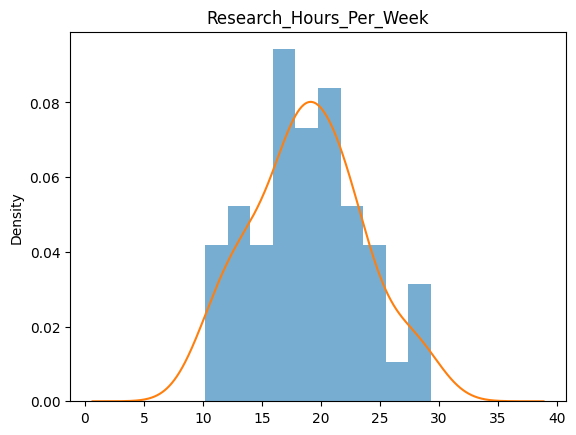

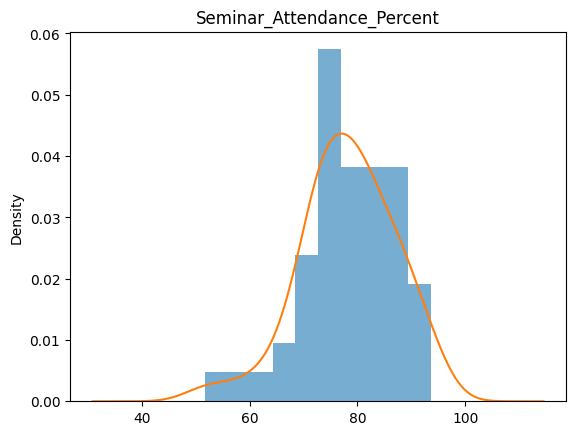

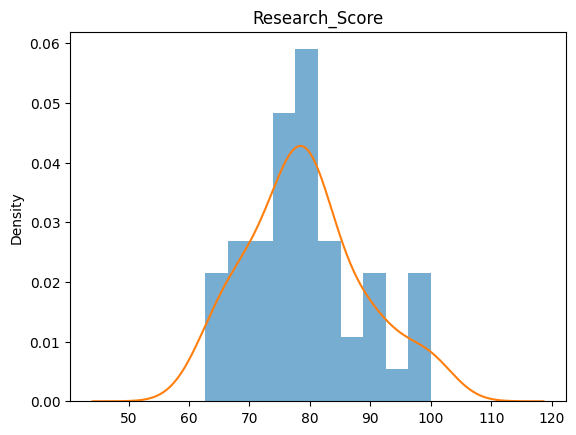

In [4]:
for c in v:
    df[c].plot(kind="hist", bins=10, density=True, alpha=0.6, title=c)
    df[c].plot(kind="kde")
    plt.show()

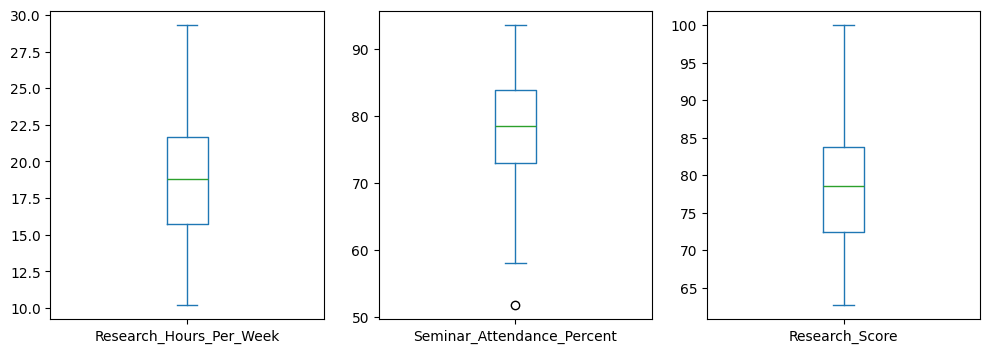

In [5]:
df[v].plot(kind="box", subplots=True, figsize=(12, 4))
plt.show()

### 3. Q-Q plots and Shapiro-Wilk test  (H0: data is normal)

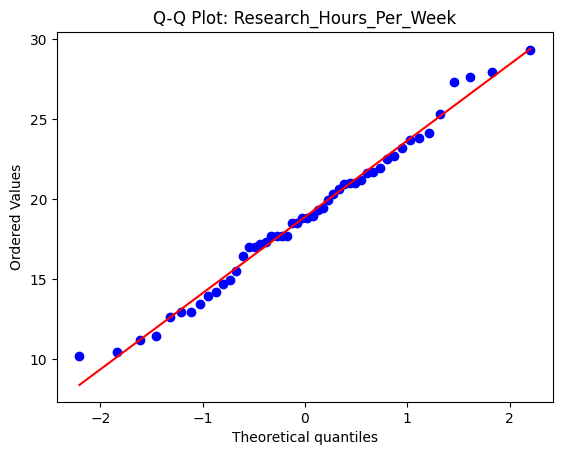

Research_Hours_Per_Week: W = 0.983, p = 0.6751 -> Normal


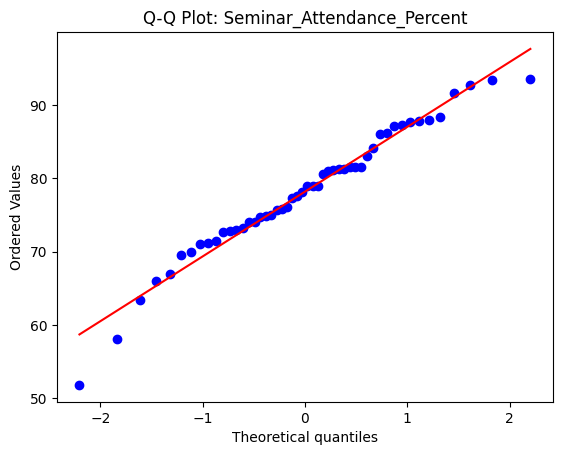

Seminar_Attendance_Percent: W = 0.971, p = 0.2576 -> Normal


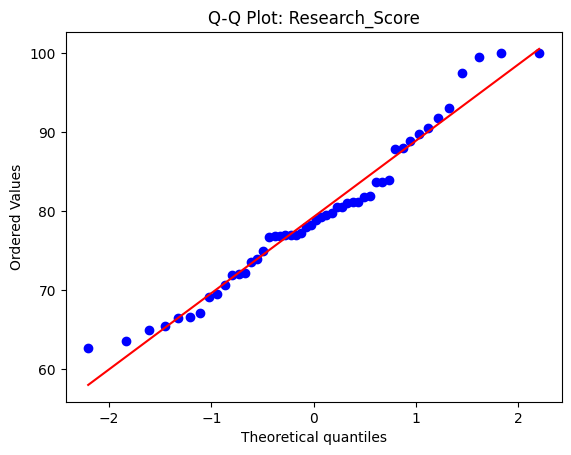

Research_Score: W = 0.963, p = 0.1183 -> Normal


In [6]:
for c in v:
    stats.probplot(df[c], dist="norm", plot=plt)
    plt.title(f"Q-Q Plot: {c}")
    plt.show()
    W, p = stats.shapiro(df[c])
    print(f"{c}: W = {W:.3f}, p = {p:.4f} ->", "Normal" if p > 0.05 else "Not normal")

### 4. Pearson and Spearman correlation

In [7]:
pairs = [("Research_Hours_Per_Week", "Research_Score"),
         ("Seminar_Attendance_Percent", "Research_Score"),
         ("Research_Hours_Per_Week", "Seminar_Attendance_Percent")]
for a, b in pairs:
    r, p1 = stats.pearsonr(df[a], df[b])
    rho, p2 = stats.spearmanr(df[a], df[b])
    print(f"{a} vs {b}\n   Pearson r = {r:.3f} (p = {p1:.4f}),  Spearman rho = {rho:.3f} (p = {p2:.4f})")

Research_Hours_Per_Week vs Research_Score
   Pearson r = 0.798 (p = 0.0000),  Spearman rho = 0.798 (p = 0.0000)
Seminar_Attendance_Percent vs Research_Score
   Pearson r = 0.145 (p = 0.3146),  Spearman rho = 0.223 (p = 0.1195)
Research_Hours_Per_Week vs Seminar_Attendance_Percent
   Pearson r = 0.111 (p = 0.4421),  Spearman rho = 0.147 (p = 0.3088)


### 5. Hypothesis test: research hours vs research score
- H0: ρ = 0 (no association)
- H1: ρ ≠ 0 (significant association), α = 0.05

In [8]:
r, p = stats.pearsonr(df["Research_Hours_Per_Week"], df["Research_Score"])
n = len(df)
t = r * np.sqrt(n - 2) / np.sqrt(1 - r**2)
print(f"r = {r:.3f}, t = {t:.3f}, df = {n - 2}, p = {p:.6f}")
print("Reject H0: significant association" if p < 0.05 else "Fail to reject H0: no significant association")

r = 0.798, t = 9.167, df = 48, p = 0.000000
Reject H0: significant association


### 6. Independent t-test: attendance < 80% vs ≥ 80%
- H0: μ_low = μ_high, H1: μ_low ≠ μ_high

In [9]:
low = df[df["Seminar_Attendance_Percent"] < 80]["Research_Score"]
high = df[df["Seminar_Attendance_Percent"] >= 80]["Research_Score"]
print(f"Low: n = {len(low)}, mean = {low.mean():.2f} | High: n = {len(high)}, mean = {high.mean():.2f}")
t, p = stats.ttest_ind(high, low)
print(f"t = {t:.3f}, p = {p:.4f} ->", "Reject H0" if p < 0.05 else "Fail to reject H0")

Low: n = 28, mean = 77.48 | High: n = 22, mean = 81.51
t = 1.506, p = 0.1386 -> Fail to reject H0


### 7. Levene's test → Welch's t-test if variances unequal

In [10]:
lev = stats.levene(low, high)
equal = lev.pvalue > 0.05
print(f"Levene p = {lev.pvalue:.4f} ->", "Equal variances: Student's t" if equal else "Unequal variances: Welch's t")
t, p = stats.ttest_ind(high, low, equal_var=equal)
print(f"t = {t:.3f}, p = {p:.4f} ->", "Reject H0" if p < 0.05 else "Fail to reject H0")

Levene p = 0.5292 -> Equal variances: Student's t
t = 1.506, p = 0.1386 -> Fail to reject H0


### 8. Scatter plots with regression lines

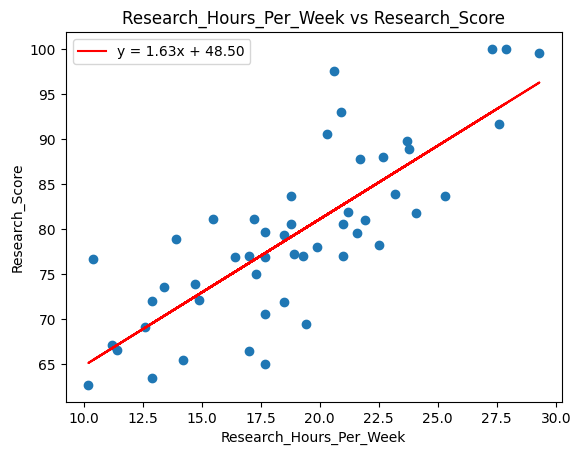

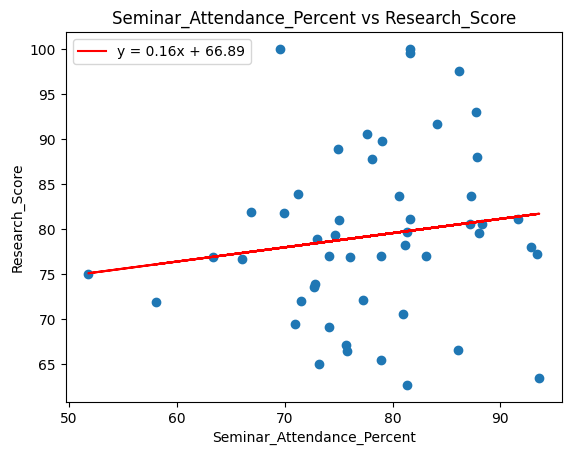

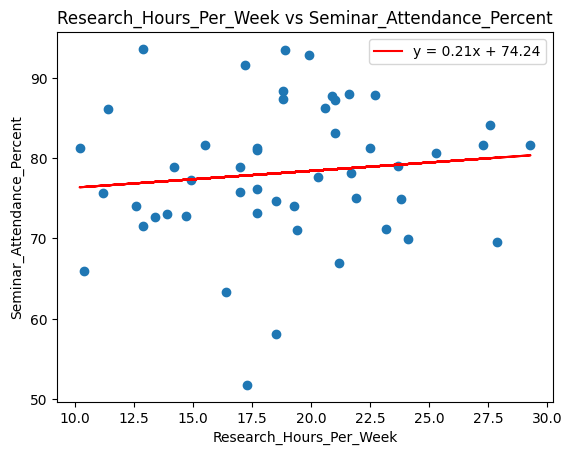

In [11]:
for a, b in pairs:
    m, c = np.polyfit(df[a], df[b], 1)
    plt.scatter(df[a], df[b])
    plt.plot(df[a], m * df[a] + c, color="red", label=f"y = {m:.2f}x + {c:.2f}")
    plt.xlabel(a)
    plt.ylabel(b)
    plt.title(f"{a} vs {b}")
    plt.legend()
    plt.show()

Upward slope → positive relationship; tighter points around the line → stronger correlation.

**Result:** Normality, correlation, hypothesis tests and group comparison (t-test, Levene, Welch) were performed successfully.